# A toy model with epistemic uncertainties, step 2: run AlTar

[Step 1](toymodel_step1.ipynb) wrote the input files to `test1`: synthetic data from a fault between two media of different shear moduli, and the Green's functions of a homogeneous half space, which are wrong for them. This step runs three static inversions with `altar.models.seismic.static`, which differ only in their prediction covariance $\mathbf{C}_\mathrm{p}$, the model's `cp`:

- `slip_cd`: none, `altar.models.cp.none`, the default; the misfit covariance is $\mathbf{C}_\mathrm{d}$, as if the Green's functions were right;
- `slip_cp_fixed`: `altar.models.cp.fixed`, the $\mathbf{C}_\mathrm{p}$ step 1 computed from the initial model;
- `slip_cp_adaptive`: `altar.models.cp.adaptive`, $\mathbf{C}_\mathrm{p}$ computed again at each $\beta$ step from the mean of the samples.

The runs take a few minutes each on a cpu.

## 1. The configuration files

Each inversion has its own configuration file for `slipmodel`, AlTar's application for slip models, and saves its samples to `results/<name>`. The one with the adaptive $\mathbf{C}_\mathrm{p}$:

In [1]:
print(open('slip_cp_adaptive.pfg').read())

;
; (c) 2013-present parasim inc
; (c) 2010-present california institute of technology
; all rights reserved
;

; the Cp toy model: C_p computed again from the mean model at each β step
slipmodel:
    ; the static model, d = G θ
    model = altar.models.seismic.static
    model:
        ; the directory with the input files from step 1
        case = test1
        ; the green's functions, (observations, parameters), for a homogeneous half space
        green = static.gf.h5

        ; the observed data
        dataobs:
            observations = 300
            data_file = static.data.h5
            cd_file = static.Cd.h5

        ; C_p from the initial model until β = 0.01, then from the mean of the samples
        cp = altar.models.cp.adaptive
        cp:
            initial_model = static.initialModel.h5
            initial_until = 0.01
        ; the covariance of the logarithms of the shear moduli, and the kernels dG/dln(mu_i)
        cmu_file = static.Cmu.h5
        kmu_file = stati

The sampler is CATMIP with Metropolis walks, as the [AlTar guide](https://altar2.readthedocs.io/en/latest/guide/Convergence.html) suggests for tens of parameters and a cheap forward model, with a decorrelating step counter: at each $\beta$ step, the chains walk until their correlation with where they started falls below 0.3.

With `cp = altar.models.cp.adaptive`, AlTar computes $\mathbf{C}_\mathrm{p} = \mathbf{K}_\mathrm{p} \mathbf{C}_\mu \mathbf{K}_\mathrm{p}^T$, with $\mathbf{K}_\mathrm{p}[:, i] = \mathbf{K}_i \boldsymbol\theta$, from the initial model until $\beta$ reaches `initial_until`, then from the mean of the samples at each $\beta$ step, and samples with the misfit covariance $\mathbf{C}_\chi = \mathbf{C}_\mathrm{d} + \mathbf{C}_\mathrm{p}$. The other two files differ only in their `cp` and their output directory:

In [2]:
import difflib
lines = lambda path: open(path).read().splitlines()
for other in ['slip_cd.pfg', 'slip_cp_fixed.pfg']:
    print('\n'.join(difflib.unified_diff(lines('slip_cp_adaptive.pfg'), lines(other), 'slip_cp_adaptive.pfg', other, n=0, lineterm='')))
    print()

--- slip_cp_adaptive.pfg
+++ slip_cd.pfg
@@ -7 +7 @@
-; the Cp toy model: C_p computed again from the mean model at each β step
+; the Cp toy model: the data covariance C_d only, no C_p
@@ -22,9 +21,0 @@
-
-        ; C_p from the initial model until β = 0.01, then from the mean of the samples
-        cp = altar.models.cp.adaptive
-        cp:
-            initial_model = static.initialModel.h5
-            initial_until = 0.01
-        ; the covariance of the logarithms of the shear moduli, and the kernels dG/dln(mu_i)
-        cmu_file = static.Cmu.h5
-        kmu_file = static.kernel.h5
@@ -57 +48 @@
-            output_dir = results/slip_cp_adaptive
+            output_dir = results/slip_cd

--- slip_cp_adaptive.pfg
+++ slip_cp_fixed.pfg
@@ -7 +7 @@
-; the Cp toy model: C_p computed again from the mean model at each β step
+; the Cp toy model: a fixed C_p, computed in step 1 from the initial model
@@ -23,2 +23,2 @@
-        ; C_p from the initial model until β = 0.01, then from the

## 2. Run AlTar

Each run goes to the shell, with its journal in a log file. (A python process holds one AlTar application, so the three runs can't share this notebook's.)

In [3]:
!slipmodel.plexus sample --config=slip_cd.pfg > slip_cd.log 2>&1

In [4]:
!slipmodel.plexus sample --config=slip_cp_fixed.pfg > slip_cp_fixed.log 2>&1

In [5]:
!slipmodel.plexus sample --config=slip_cp_adaptive.pfg > slip_cp_adaptive.log 2>&1

## 3. How the runs went

The `diagnose` action reads the steps a run archived and reports its annealing schedule, step by step: $\beta$, the acceptance rate of the walks, the spread of the importance weights, the evidence, and how well the walks mixed, `corr` and `max`, the median and largest correlation over the parameters between the end of each chain's walk and its start. For the adaptive run:

In [6]:
!slipmodel.plexus diagnose --config=slip_cp_adaptive.pfg --slipmodel.diagnose.theta=results/slip_cp_adaptive/step_final.h5 \
    --slipmodel.diagnose.output=results/slip_cp_adaptive/diagnose.h5 > diagnose.log 2>&1
!grep -v -E "^journal|^\s*$" diagnose.log | sed -e 's/^ -- //'

diagnose: 'results/slip_cp_adaptive/step_final.h5', 7 archived steps
   step        beta  acceptance   scaling   cov(w)   ESS/N    log evidence  parents  lineages   corr    max  states
    000           0         nan       nan      nan     nan               0      nan       nan    nan    nan     nan
    001   0.0003974       0.023    0.4311    1.005   0.497        -2.27724      577       577  0.005  0.078     nan
    002     0.01822       0.299    0.4602    1.005   0.497          1.8469      590       432 -0.000  0.061     nan
    003     0.08341       0.313    0.4979    1.002   0.499         20.7964      597       348  0.002  0.061     nan
    004       0.283       0.281    0.5218    1.003   0.498         81.5891      598       281  0.011  0.082     nan
    005      0.8032       0.254    0.5326    1.002   0.499         242.102      597       243  0.001  0.068     nan
    006           1       0.246     0.539    0.234   0.948         303.065      929       240  0.015  0.081     nan
  (

The walks decorrelated the chains at every step, the largest correlation with their start below 0.1. The low acceptance rate of the first step is the proposal adapting: it starts from the spread of the initial samples, and reaches the Metropolis target, about 0.25, at the next steps.

## 4. The inferred slip

The samples of the posterior are in `results/<name>/step_final.h5`. The values AlTar samples are in `ParameterSets/strikeslip_sampling`; with a gaussian prior, they are the slips themselves, and with a reparameterized one, e.g. a uniform prior in logit space, the slips are in `ParameterSets/strikeslip_physical`:

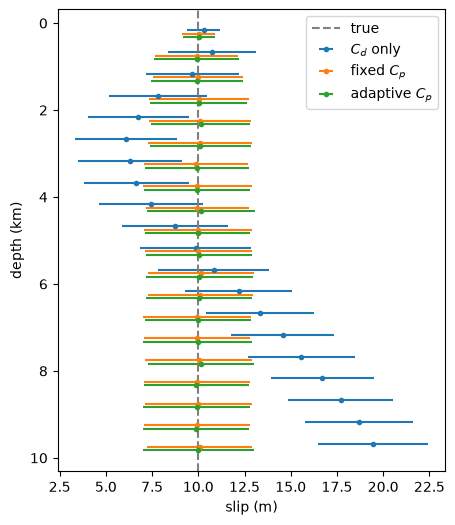

          slip_cd: mean slip  11.47 m, mean sd  2.71 m; 4 of 20 patches more than 2 sd from the true slip
    slip_cp_fixed: mean slip  10.00 m, mean sd  2.71 m; 0 of 20 patches more than 2 sd from the true slip
 slip_cp_adaptive: mean slip  10.00 m, mean sd  2.70 m; 0 of 20 patches more than 2 sd from the true slip


In [7]:
import numpy as np
import h5py
import matplotlib.pyplot as plt

names = {'slip_cd': '$C_d$ only', 'slip_cp_fixed': 'fixed $C_p$', 'slip_cp_adaptive': 'adaptive $C_p$'}
theta = {}
for name in names:
    with h5py.File(f'results/{name}/step_final.h5') as h5:
        sets = h5['ParameterSets']
        theta[name] = np.asarray(sets['strikeslip_physical'] if 'strikeslip_physical' in sets else sets['strikeslip_sampling'])

# the depth of the center of each patch, in km
patches, width = 20, 10.0
depth = (np.arange(patches) + 0.5) * width / patches
fig, ax = plt.subplots(figsize=(5, 6))
for offset, (name, label) in zip((-0.08, 0, 0.08), names.items()):
    ax.errorbar(theta[name].mean(0), depth + offset, xerr=theta[name].std(0), fmt='o', ms=3, label=label)
ax.axvline(10.0, color='gray', ls='--', label='true')
ax.invert_yaxis()
ax.set_xlabel('slip (m)'); ax.set_ylabel('depth (km)'); ax.legend()
plt.show()

for name, label in names.items():
    t = theta[name]
    z = np.abs(t.mean(0) - 10.0) / t.std(0)
    print(f"{name:>17}: mean slip {t.mean():6.2f} m, mean sd {t.std(0).mean():5.2f} m; "
          f"{(z > 2).sum()} of {patches} patches more than 2 sd from the true slip")

## 5. The fit to the data

The `forward` action runs the model on the posterior mean and on the samples, and reports the fit with the run's own misfit covariance: $\mathbf{C}_\mathrm{d}$ for `slip_cd`, $\mathbf{C}_\chi = \mathbf{C}_\mathrm{d} + \mathbf{C}_\mathrm{p}$ for the other two, with the adaptive $\mathbf{C}_\mathrm{p}$ estimated at the posterior mean:

In [8]:
for name in names:
    !slipmodel.plexus forward --config={name}.pfg --slipmodel.forward.theta=results/{name}/step_final.h5 \
        --slipmodel.forward.output=results/{name}/forward.h5 > {name}.forward.log 2>&1
    print(f"== {name}")
    !grep -E "chi\^2/N|mean model|predictive band" {name}.forward.log | grep -v "^journal" | sed -e 's/^ -- //'

== slip_cd


                           chi^2/N        VR         rms         log L
  mean model                 19.74    0.8547      0.6144      -2642.48
  samples: log L -2644.04 +- 4.98, chi^2/N median 19.74; 2 var(log L) = 49.6 (the effective number of parameters, for a gaussian posterior)
observations within the predictive band: 66.7% at 1 sigma, 71.3% at 2 sigma


== slip_cp_fixed


                           chi^2/N        VR         rms         log L
  mean model               0.07324    0.8493      0.6257       303.986
  samples: log L 302.423 +- 1.12, chi^2/N median 0.08193; 2 var(log L) = 2.52 (the effective number of parameters, for a gaussian posterior)
observations within the predictive band: 66.7% at 1 sigma, 66.7% at 2 sigma


== slip_cp_adaptive


                           chi^2/N        VR         rms         log L
  mean model               0.01836    0.8493      0.6257       311.525
  samples: log L 309.928 +- 1.14, chi^2/N median 0.0272; 2 var(log L) = 2.6 (the effective number of parameters, for a gaussian posterior)
observations within the predictive band: 66.7% at 1 sigma, 76.0% at 2 sigma


The predictions of the mean models along strike, against the data, with the band of $\mathbf{C}_\chi$ for the adaptive run (the predictions of the two runs with $\mathbf{C}_\mathrm{p}$ overlap); and the chi-square per datum of each mean model with $\mathbf{C}_\mathrm{d}$ alone, the same yardstick for the three:

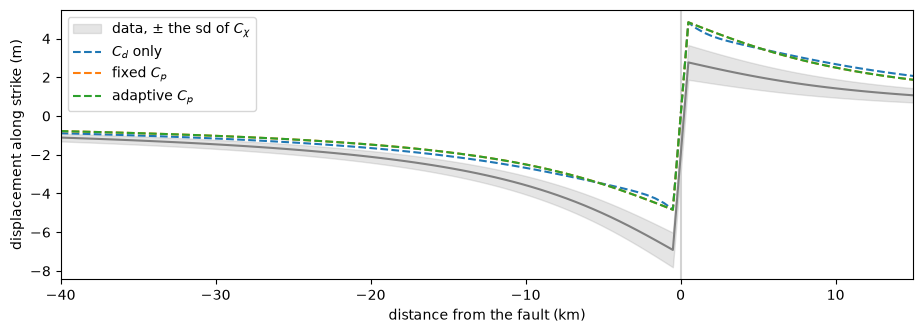

          slip_cd: chi-square per datum with C_d alone  19.74
    slip_cp_fixed: chi-square per datum with C_d alone  20.46
 slip_cp_adaptive: chi-square per datum with C_d alone  20.47


In [9]:
x = np.concatenate((np.linspace(-40e3, -500, 70), np.linspace(500, 15e3, 30)))
x3 = slice(100, 200)  # the component along strike, the second third of the observations
fit = {}
for name in names:
    with h5py.File(f'results/{name}/forward.h5') as h5:
        fit[name] = {k: np.asarray(h5[k]) for k in ['data/observed', 'data/mean_model', 'data/sigma', 'data/sigma_chi']}
observed, sigma = fit['slip_cd']['data/observed'], fit['slip_cd']['data/sigma']

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.axvline(0, color='lightgray')
band = fit['slip_cp_adaptive']['data/sigma_chi'][x3]
ax.fill_between(x / 1e3, observed[x3] - band, observed[x3] + band, color='gray', alpha=0.2, label=r'data, $\pm$ the sd of $C_\chi$')
ax.plot(x / 1e3, observed[x3], color='gray')
for name, label in names.items():
    ax.plot(x / 1e3, fit[name]['data/mean_model'][x3], '--', label=label)
ax.set_xlim(-40, 15)
ax.set_xlabel('distance from the fault (km)'); ax.set_ylabel('displacement along strike (m)'); ax.legend()
plt.show()

for name in names:
    r = (fit[name]['data/mean_model'] - observed) / sigma
    print(f"{name:>17}: chi-square per datum with C_d alone {(r ** 2).mean():6.2f}")

## 6. Discussion

Ignoring the epistemic uncertainties, the inversion with $\mathbf{C}_\mathrm{d}$ alone is biased. The homogeneous Green's functions under-predict the displacements on the compliant West side of the fault and over-predict them on the stiff East side, and no slip model fits both sides. Since the network covers the West side better, the inversion trades one side against the other with a distorted slip distribution, too little slip between 1.5 and 4.5 km and too much below 6 km, 4 of its patches more than 2 standard deviations from the true slip, for hardly any gain in the fit: its chi-square per datum with $\mathbf{C}_\mathrm{d}$, 19.7, is barely lower than that of the other two, 20.5. Its posterior is confidently wrong.

With $\mathbf{C}_\mathrm{p}$, fixed or adaptive, the inversion recovers the true slip within its uncertainties, a mean slip of 10.00 m. The mean models miss the data point by point as much as the one with $\mathbf{C}_\mathrm{d}$ alone, outside the band of $\mathbf{C}_\chi$ along strike; but the misfit lies along the one direction $\mathbf{C}_\mathrm{p}$ describes, the change of the predictions with the ratio of the shear moduli (the two kernels are opposite, so $\mathbf{C}_\mathrm{p}$ has rank 1), and $\mathbf{C}_\chi$ expects it: a chi-square of 22 over the 300 data with the fixed $\mathbf{C}_\mathrm{p}$, and 5.5 with the adaptive one. The adaptive $\mathbf{C}_\mathrm{p}$, computed from a mean model of 10 m rather than the initial 5 m, is four times the fixed one, and explains the misfit better.

The fixed and the adaptive $\mathbf{C}_\mathrm{p}$ give the same slip here because the initial model, a uniform slip of 5 m, has the shape of the true slip: the shape of the slip model sets the direction of $\mathbf{C}_\mathrm{p}$, and its size only the amplitude. For an initial model whose shape differs from the solution, updating $\mathbf{C}_\mathrm{p}$ during the sampling matters.

In all three runs, the standard deviations of the deep patches stay close to the 3 m of the prior: the surface data hardly constrain the slip at depth, whatever the covariance.